In [33]:
# Import modules
import numpy as np
import matplotlib.pyplot as plt
import numpy as np

In [34]:
lim1 = np.deg2rad(170)
lim2 = np.deg2rad(120)
lim3 = np.deg2rad(170)
lim4 = np.deg2rad(120)
lim5 = np.deg2rad(170)
lim6 = np.deg2rad(120)
lim7 = np.deg2rad(175)

constraints = (np.array([-lim1 , -lim2 , -lim3 , -lim4 , -lim5 , -lim6, -lim7]),
               np.array([ lim1  , lim2 ,  lim3 ,  lim4 ,  lim5 ,  lim6,  lim7]))

initial_joint_angles = [0.,0.,0.,0.,0.,0.,0.]
d2 = d4 = d4 = d6 = 0.03
d1 = 0.34
d3 = 0.4
d5 = 0.4
d7 = 0.126

In [35]:
def getTransformMatrix(theta, d, a, alpha):
    T = np.array([[np.cos(theta) , -np.sin(theta)*np.cos(alpha) ,  np.sin(theta)*np.sin(alpha) , a*np.cos(theta)],
                  [np.sin(theta) ,  np.cos(theta)*np.cos(alpha) , -np.cos(theta)*np.sin(alpha) , a*np.sin(theta)],
                  [0             ,  np.sin(alpha)               ,  np.cos(alpha)               , d              ],
                  [0             ,  0                           ,  0                           , 1              ]
                 ])
    return T

def get_end_tip_position(params):
    # Create the transformation matrices for the respective joints
    t_00 = np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,1]])
    t_01 = getTransformMatrix(params[0] , d1  , 0 , -np.pi/2)
    t_12 = getTransformMatrix(params[1] , d2  , 0 ,  np.pi/2)
    t_23 = getTransformMatrix(params[2] , d3  , 0 ,  np.pi/2)
    t_34 = getTransformMatrix(params[3] , d4  , 0 , -np.pi/2)
    t_45 = getTransformMatrix(params[4] , d5  , 0 , -np.pi/2)
    t_56 = getTransformMatrix(params[5] , d6  , 0 ,  np.pi/2)
    t_67 = getTransformMatrix(params[6] , d7  , 0 ,        0)

    # Get the overall transformation matrix
    end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)

    # The coordinates of the end tip are the 3 upper entries in the 4th column
    pos = np.array([end_tip_m[0,3],end_tip_m[1,3],end_tip_m[2,3]])
    return pos

def get_nth_position(params,n):
    # Create the transformation matrices for the respective joints
    t_00 = np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,1]])
    t_01 = getTransformMatrix(params[0] , d1  , 0 , -np.pi/2)
    t_12 = getTransformMatrix(params[1] , d2  , 0 ,  np.pi/2)
    t_23 = getTransformMatrix(params[2] , d3  , 0 ,  np.pi/2)
    t_34 = getTransformMatrix(params[3] , d4  , 0 , -np.pi/2)
    t_45 = getTransformMatrix(params[4] , d5  , 0 , -np.pi/2)
    t_56 = getTransformMatrix(params[5] , d6  , 0 ,  np.pi/2)
    t_67 = getTransformMatrix(params[6] , d7  , 0 ,        0)

    if n==0:
        end_tip_m = t_00#.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==1:
        end_tip_m = t_00.dot(t_01)#.dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==2:
        end_tip_m = t_00.dot(t_01).dot(t_12)#.dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==3:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23)#.dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    elif n==4:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34)#.dot(t_45).dot(t_56).dot(t_67)
    elif n==5:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45)#.dot(t_56).dot(t_67)
    elif n==6:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56)#.dot(t_67)
    elif n==7:
        end_tip_m = t_00.dot(t_01).dot(t_12).dot(t_23).dot(t_34).dot(t_45).dot(t_56).dot(t_67)
    else:
        print('no more tf')
        
    # The coordinates of the end tip are the 3 upper entries in the 4th column
    pos = np.array([end_tip_m[0,3],end_tip_m[1,3],end_tip_m[2,3]])
    return pos

def distance(query, target):
    x_dist = (target[0] - query[0])**2
    y_dist = (target[1] - query[1])**2
    z_dist = (target[2] - query[2])**2
    dist = np.sqrt(x_dist + y_dist + z_dist)
    return dist

def opt_func(X):
    n_particles = X.shape[0]  # number of particles
    dist = [distance(get_end_tip_position(X[i]), target_position) for i in range(n_particles)]
    return np.array(dist)

# Plot the resulting joint configuration and end pose.
def visualize_config(sol, target, alg):
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(projection='3d')
    for i in range(7):
        point = get_nth_position(sol,i)
        point_n = get_nth_position(sol,i+1)
        print(f"{i}: {point}")
        x,y,z = [point[0],point_n[0]], [point[1],point_n[1]], [point[2],point_n[2]]
        ax.scatter(x, y, z, c='red', s=100)
        ax.plot(x, y, z, color='black',linewidth=4)
        if i==6:
            ax.scatter(point_n[0], point_n[1], point_n[2], c='red', s=120)

    ax.scatter(0,0,0)
    ax.scatter(target[0],target[1],target[2],c='green', s=260)

    fig.suptitle('Arm Visualization via {}'.format(alg))
    ax.set_xlabel('X Label')
    ax.set_ylabel('Y Label', fontsize=10)
    ax.set_zlabel('Z Label', fontsize=10)
    plt.show()

In [36]:
def cost_function(joint_angles, target_position, forward_kinematics):
    """
    Calculate the cost based on the current and target positions.
    """
    current_position = forward_kinematics(joint_angles)
    return np.linalg.norm(current_position - target_position)

def gradient_descent(target_position, initial_joint_angles, forward_kinematics, iterations=100, learning_rate=0.01):
    """
    Perform inverse kinematics by optimizing the joint angles to minimize the distance
    to the target position using gradient descent.
    """
    joint_angles = np.array(initial_joint_angles)
    cost_history = []  # Initialize an empty list to store the cost history
        
    for _ in range(iterations):
        # Calculate the gradient of the cost function
        gradient = np.zeros(joint_angles.shape)
        
        # Calculate the current cost
        current_cost = cost_function(joint_angles, target_position, forward_kinematics)
        cost_history.append(current_cost)  # Append the current cost to the history
    
        for i in range(len(joint_angles)):
            # Perturbation method for gradient approximation
            original_angle = joint_angles[i]
            joint_angles[i] += 0.01
            cost_plus = cost_function(joint_angles, target_position, forward_kinematics)
            joint_angles[i] = original_angle - 0.01
            cost_minus = cost_function(joint_angles, target_position, forward_kinematics)
            joint_angles[i] = original_angle
            
            # Approximate derivative
            gradient[i] = (cost_plus - cost_minus) / 0.02
        
        # Update the joint angles based on the gradient
        joint_angles -= learning_rate * gradient

        # Optional: Implement a convergence check

    return joint_angles, cost_history



joint_vars: 
[-0.45551862  0.78718656 -0.26644805 -1.71869523 -0.10082034  0.55536454
  0.        ]

End position for joint angles: 
[ 0.4161307  -0.32185773  0.18684803]

0: [0 0 0]
1: [0.   0.   0.34]
2: [0.01319784 0.02694099 0.34      ]
3: [ 0.26765378 -0.0977118   0.62233642]
4: [ 0.24991461 -0.12124925  0.62793198]
5: [ 0.40851934 -0.31494755  0.31596161]
6: [ 0.42404804 -0.29036042  0.30859053]


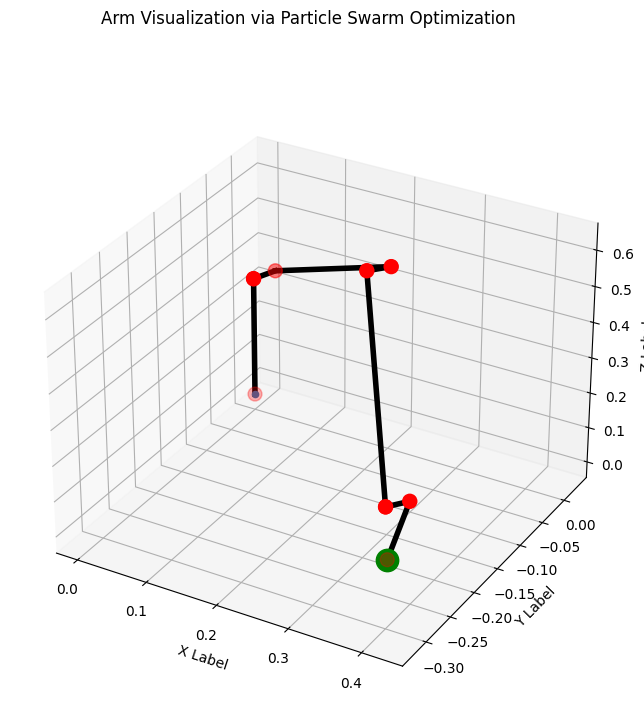

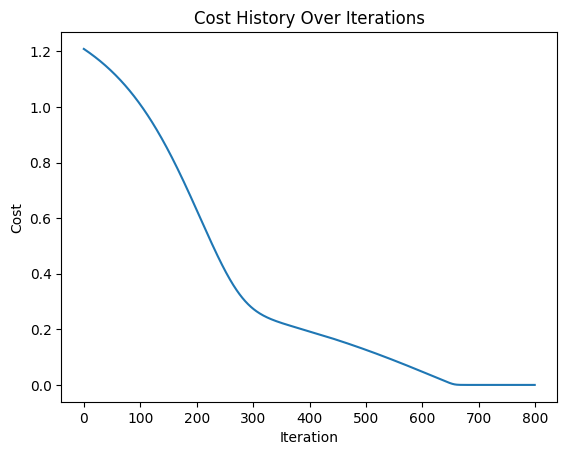

In [46]:
# Target position and orientation  
# Workspace range
x, y, z = np.random.uniform(-0.5,0.5), np.random.uniform(-0.5,0.5), np.random.uniform(-0.15,0.2)
target_position = np.array([x,y,z])

joint_angles, cost_history = gradient_descent(target_position, initial_joint_angles, get_end_tip_position, iterations=800, learning_rate=0.01)

print(f"joint_vars: \n{joint_angles}")
print(f"\nEnd position for joint angles: \n{get_end_tip_position(joint_angles)}\n")

visualize_config(joint_angles, target_position, 'Particle Swarm Optimization')

plt.plot(cost_history)
plt.xlabel('Iteration')
plt.ylabel('Cost')
plt.title('Cost History Over Iterations')
plt.show()